# 2. Explore the Data

Check the churn rate, see how it changes with tenure, and review correlations between numeric features. We only remove a feature if its correlation with another feature is above 0.85.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_DIR = Path.cwd().parent
data_file = PROJECT_DIR / "Cleaned_Datasets" / "telco_customer_churn.csv"
data = pd.read_csv(data_file)
display(data.head())

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


## Churn rate

Churn rate: 26.5%


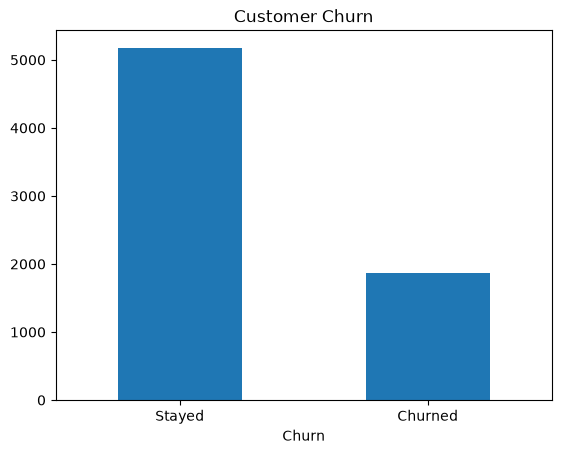

In [2]:
print(f"Churn rate: {data['Churn'].mean():.1%}")
data["Churn"].value_counts().sort_index().plot(kind="bar")
plt.xticks([0, 1], ["Stayed", "Churned"], rotation=0)
plt.title("Customer Churn")
plt.show()

## Churn by tenure

tenure
0-12     0.47
13-24    0.29
25-48    0.20
49-72    0.10
Name: Churn, dtype: float64


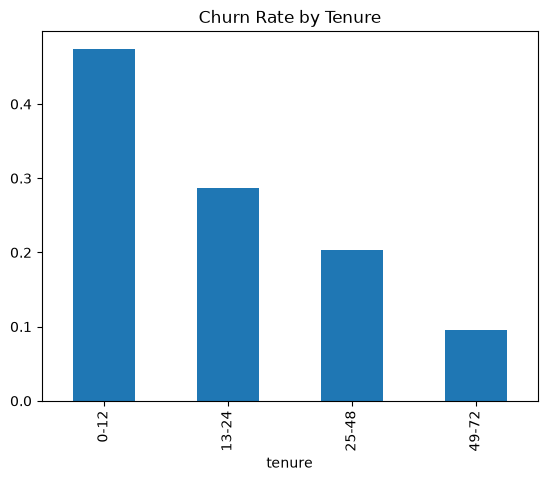

In [3]:
tenure_group = pd.cut(
    data["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12", "13-24", "25-48", "49-72"],
)
churn_by_tenure = data.groupby(tenure_group, observed=False)["Churn"].mean()
print(churn_by_tenure.round(2))
churn_by_tenure.plot(kind="bar")
plt.title("Churn Rate by Tenure")
plt.show()

## Correlation heat map

The heat map includes `Churn` for exploration. We only check correlations between predictors before removing anything.

In [4]:
correlations = data.corr(numeric_only=True)
display(correlations.style.background_gradient(cmap="coolwarm", vmin=-1, vmax=1))

tenure_charge_correlation = abs(data["tenure"].corr(data["TotalCharges"]))
print(f"Tenure and TotalCharges correlation: {tenure_charge_correlation:.2f}")

if tenure_charge_correlation > 0.85:
    data = data.drop(columns="TotalCharges")
    print("Removed TotalCharges because it is highly correlated with tenure.")
else:
    print("Kept both features; their correlation is below 0.85.")

data.to_csv(data_file, index=False)

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn
SeniorCitizen,1.000000,0.016567,0.220173,0.102411,0.150889
tenure,0.016567,1.000000,0.247900,0.825880,-0.352229
MonthlyCharges,0.220173,0.247900,1.000000,0.651065,0.193356
TotalCharges,0.102411,0.825880,0.651065,1.000000,-0.199484
Churn,0.150889,-0.352229,0.193356,-0.199484,1.000000


Tenure and TotalCharges correlation: 0.83
Kept both features; their correlation is below 0.85.
